In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [10]:
df= pd.read_csv("Food_Delivery_Times.csv")

In [11]:
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [12]:
df.isnull().sum()

Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64

In [13]:
df.columns

Index(['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs',
       'Delivery_Time_min'],
      dtype='object')

In [14]:
# 1. Fill categorical columns with their mode
categorical_cols = ['Weather', 'Traffic_Level', 'Time_of_Day']
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# 2. Fill numerical column with its median
df['Courier_Experience_yrs'] = df['Courier_Experience_yrs'].fillna(df['Courier_Experience_yrs'].median())

# 3. Drop the Order_ID column
df = df.drop(columns=['Order_ID'])

# Verify there are no more missing values and check the remaining columns
print(df.isnull().sum())
df.head()

Distance_km               0
Weather                   0
Traffic_Level             0
Time_of_Day               0
Vehicle_Type              0
Preparation_Time_min      0
Courier_Experience_yrs    0
Delivery_Time_min         0
dtype: int64


,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,19.03,Clear,Low,Morning,Bike,16,5.0,68


,count,mean,std,min,25%,50%,75%,max
Distance_km,1000.0,10.05997,5.696656,0.59,5.105,10.19,15.0175,19.99
Preparation_Time_min,1000.0,16.98200,7.204553,5.00,11.000,17.00,23.0000,29.00
Courier_Experience_yrs,1000.0,4.59200,2.871198,0.00,2.000,5.00,7.0000,9.00
Delivery_Time_min,1000.0,56.73200,22.070915,8.00,41.000,55.50,71.0000,153.00


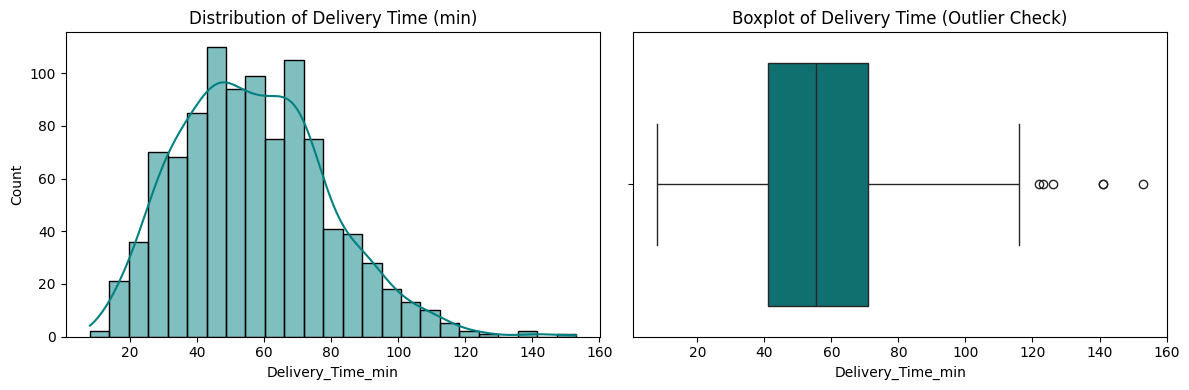

In [15]:
# Summary statistics for numerical features
display(df.describe().T)

# Target variable distribution (Histogram + Boxplot)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['Delivery_Time_min'], kde=True, ax=axes[0], color='teal')
axes[0].set_title('Distribution of Delivery Time (min)')

sns.boxplot(x=df['Delivery_Time_min'], ax=axes[1], color='teal')
axes[1].set_title('Boxplot of Delivery Time (Outlier Check)')

plt.tight_layout()
plt.show()

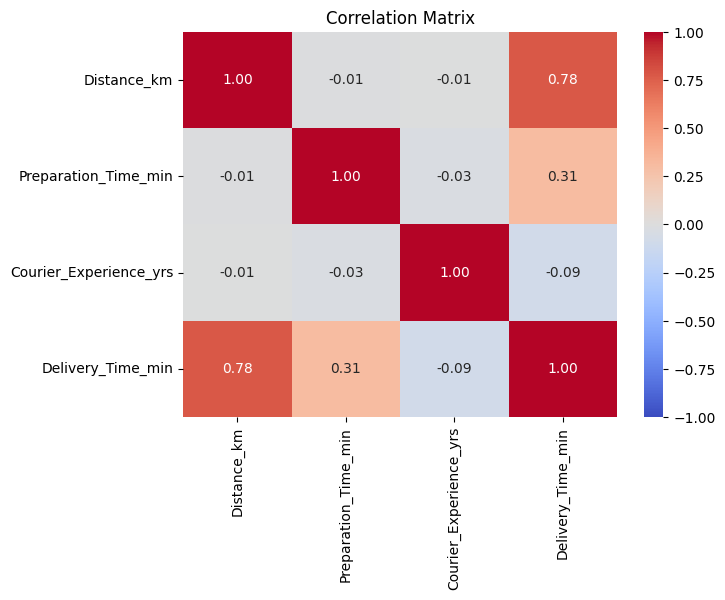

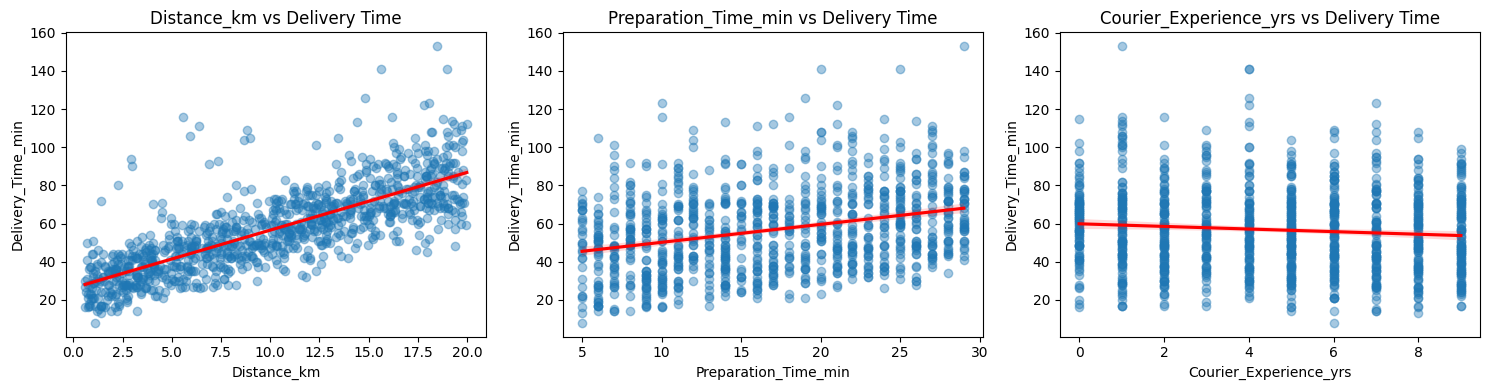

In [16]:
num_cols = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Delivery_Time_min']

# Correlation Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

# Scatterplots against the target
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
features = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']

for i, col in enumerate(features):
    sns.regplot(data=df, x=col, y='Delivery_Time_min', ax=axes[i], 
                scatter_kws={'alpha': 0.4}, line_kws={'color': 'red'})
    axes[i].set_title(f'{col} vs Delivery Time')

plt.tight_layout()
plt.show()

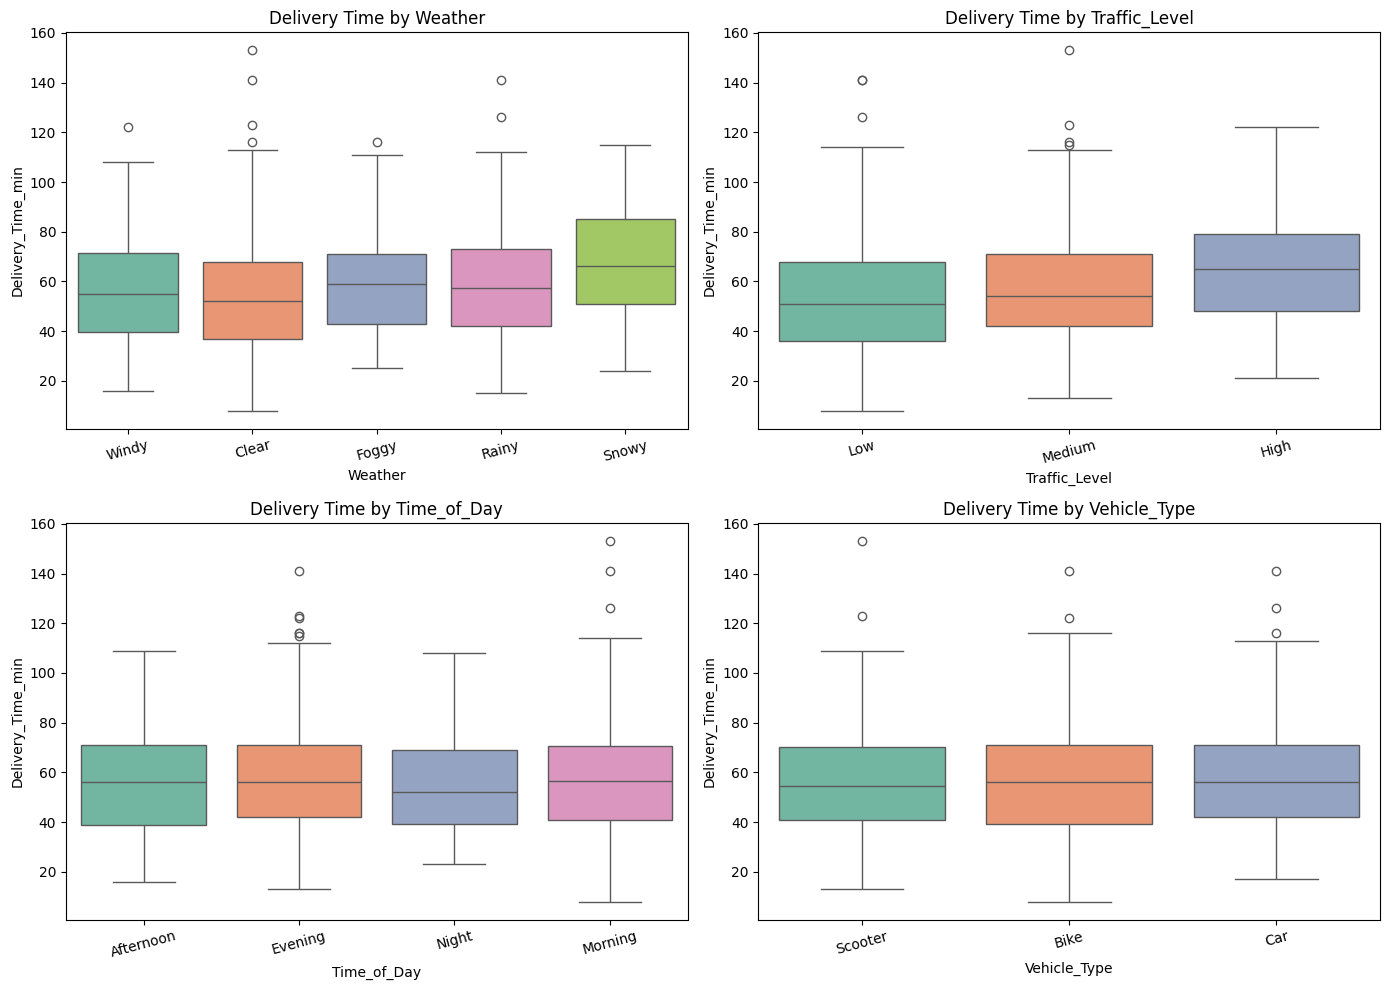


--- Weather ---
         count       mean  median
Weather                          
Clear      500  53.150000    52.0
Foggy      103  59.466019    59.0
Rainy      204  59.794118    57.5
Snowy       97  67.113402    66.0
Windy       96  55.458333    55.0

--- Traffic_Level ---
               count       mean  median
Traffic_Level                          
High             197  64.807107    65.0
Low              383  52.885117    51.0
Medium           420  56.452381    54.0

--- Time_of_Day ---
             count       mean  median
Time_of_Day                          
Afternoon      284  56.080986    56.0
Evening        293  57.481229    56.0
Morning        338  57.011834    56.5
Night           85  55.211765    52.0

--- Vehicle_Type ---
              count       mean  median
Vehicle_Type                          
Bike            503  56.574553    56.0
Car             195  58.200000    56.0
Scooter         302  56.046358    54.5


In [17]:
cat_cols = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.boxplot(data=df, x=col, y='Delivery_Time_min', ax=axes[i], palette='Set2')
    axes[i].set_title(f'Delivery Time by {col}')
    axes[i].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# Print average delivery time and sample count per category
for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df.groupby(col)['Delivery_Time_min'].agg(['count', 'mean', 'median']))

In [18]:
from scipy import stats

target = 'Delivery_Time_min'

# 1. Statistical Tests for Numerical Features (Pearson & Spearman)
num_features = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']
num_results = []

for col in num_features:
    pearson_r, pearson_p = stats.pearsonr(df[col], df[target])
    spearman_r, spearman_p = stats.spearmanr(df[col], df[target])
    num_results.append({
        'Feature': col,
        'Pearson_r': round(pearson_r, 4),
        'Pearson_p_value': f"{pearson_p:.4e}",
        'Spearman_r': round(spearman_r, 4),
        'Spearman_p_value': f"{spearman_p:.4e}",
        'Significant (p < 0.05)': 'Yes' if pearson_p < 0.05 else 'No'
    })

print("=== NUMERICAL FEATURES (CORRELATION TESTS) ===")
display(pd.DataFrame(num_results))

# 2. Statistical Tests for Categorical Features (ANOVA & Kruskal-Wallis)
cat_features = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
cat_results = []

for col in cat_features:
    # Split target values into groups based on category
    groups = [group[target].values for name, group in df.groupby(col)]
    
    f_stat, anova_p = stats.f_oneway(*groups)
    kw_stat, kw_p = stats.kruskal(*groups)
    cat_results.append({
        'Feature': col,
        'ANOVA_F_stat': round(f_stat, 4),
        'ANOVA_p_value': f"{anova_p:.4e}",
        'Kruskal_stat': round(kw_stat, 4),
        'Kruskal_p_value': f"{kw_p:.4e}",
        'Significant (p < 0.05)': 'Yes' if anova_p < 0.05 else 'No'
    })

print("\n=== CATEGORICAL FEATURES (ANOVA & KRUSKAL-WALLIS) ===")
display(pd.DataFrame(cat_results))

=== NUMERICAL FEATURES (CORRELATION TESTS) ===


,Feature,Pearson_r,Pearson_p_value,Spearman_r,Spearman_p_value,Significant (p < 0.05)
0,Distance_km,0.7810,2.9763e-206,0.8165,2.3195e-240,Yes
1,Preparation_Time_min,0.3073,2.5499e-23,0.3055,4.7323e-23,Yes
2,Courier_Experience_yrs,-0.0891,4.8018e-03,-0.0855,6.7976e-03,Yes



=== CATEGORICAL FEATURES (ANOVA & KRUSKAL-WALLIS) ===


,Feature,ANOVA_F_stat,ANOVA_p_value,Kruskal_stat,Kruskal_p_value,Significant (p < 0.05)
0,Weather,10.4991,2.4723e-08,37.0454,1.7629e-07,Yes
1,Traffic_Level,19.7513,3.8697e-09,37.0658,8.9385e-09,Yes
2,Time_of_Day,0.3468,7.9151e-01,0.9383,8.1618e-01,No
3,Vehicle_Type,0.5894,5.5487e-01,0.9852,6.1103e-01,No


In [19]:
from sklearn.preprocessing import LabelEncoder

# Identify categorical columns in your dataset
cat_cols = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']

# Store encoders in a dictionary in case you want to check the mappings or inverse_transform later
encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le
    # Print the assigned integer mapping for reference
    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    print(f"{col} mapping: {mapping}")

# Check the updated dataframe
df.head()

Weather mapping: {'Clear': 0, 'Foggy': 1, 'Rainy': 2, 'Snowy': 3, 'Windy': 4}
Traffic_Level mapping: {'High': 0, 'Low': 1, 'Medium': 2}
Time_of_Day mapping: {'Afternoon': 0, 'Evening': 1, 'Morning': 2, 'Night': 3}
Vehicle_Type mapping: {'Bike': 0, 'Car': 1, 'Scooter': 2}


,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,7.93,4,1,0,2,12,1.0,43
1,16.42,0,2,1,0,20,2.0,84
2,9.52,1,1,3,2,28,1.0,59
3,7.44,2,2,0,2,5,1.0,37
4,19.03,0,1,2,0,16,5.0,68


In [22]:
from sklearn.model_selection import train_test_split

# 1. Define features (X)

X = df.drop('Delivery_Time_min',axis=1)
y = df['Delivery_Time_min']

# 2. Split the data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Verify the shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (800, 7)
X_test shape: (200, 7)
y_train shape: (800,)
y_test shape: (200,)


In [23]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Initialize the Decision Tree Regressor with completely default parameters
dt_model = DecisionTreeRegressor()

# 2. Train the model on the training data
dt_model.fit(X_train, y_train)

# 3. Make predictions on both training and test sets
y_train_pred = dt_model.predict(X_train)
y_test_pred = dt_model.predict(X_test)

# 4. Evaluate performance
print("=== TRAINING PERFORMANCE ===")
print(f"Train R² Score: {r2_score(y_train, y_train_pred):.4f}")
print(f"Train MAE:      {mean_absolute_error(y_train, y_train_pred):.4f} min")

print("\n=== TESTING PERFORMANCE ===")
print(f"Test R² Score:  {r2_score(y_test, y_test_pred):.4f}")
print(f"Test MAE:       {mean_absolute_error(y_test, y_test_pred):.4f} min")
print(f"Test RMSE:      {np.sqrt(mean_squared_error(y_test, y_test_pred)):.4f} min")

=== TRAINING PERFORMANCE ===
Train R² Score: 1.0000
Train MAE:      0.0000 min

=== TESTING PERFORMANCE ===
Test R² Score:  0.5136
Test MAE:       10.3550 min
Test RMSE:      14.7657 min


In [24]:
from sklearn.ensemble import RandomForestRegressor

# 1. Initialize the Random Forest Regressor with completely default parameters
rf_model = RandomForestRegressor()

# 2. Train the model on the training data
rf_model.fit(X_train, y_train)

# 3. Make predictions on both training and test sets
y_train_pred_rf = rf_model.predict(X_train)
y_test_pred_rf = rf_model.predict(X_test)

# 4. Evaluate performance
print("=== RANDOM FOREST TRAINING PERFORMANCE ===")
print(f"Train R² Score: {r2_score(y_train, y_train_pred_rf):.4f}")
print(f"Train MAE:      {mean_absolute_error(y_train, y_train_pred_rf):.4f} min")

print("\n=== RANDOM FOREST TESTING PERFORMANCE ===")
print(f"Test R² Score:  {r2_score(y_test, y_test_pred_rf):.4f}")
print(f"Test MAE:       {mean_absolute_error(y_test, y_test_pred_rf):.4f} min")
print(f"Test RMSE:      {np.sqrt(mean_squared_error(y_test, y_test_pred_rf)):.4f} min")

=== RANDOM FOREST TRAINING PERFORMANCE ===
Train R² Score: 0.9555
Train MAE:      3.0962 min

=== RANDOM FOREST TESTING PERFORMANCE ===
Test R² Score:  0.7807
Test MAE:       7.0362 min
Test RMSE:      9.9143 min


In [25]:
from sklearn.model_selection import RandomizedSearchCV

# 1. Define a rich hyperparameter search space
param_dist = {
    'n_estimators': [100, 200, 300, 400, 500],
    'max_depth': [4, 6, 8, 10, 12, 15, 20, None],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf': [1, 2, 4, 6, 8],
    'max_features': ['sqrt', 'log2', 0.6, 0.8, 1.0],
    'bootstrap': [True, False]
}

# 2. Run RandomizedSearchCV (50 iterations x 5 folds = 250 fits)
rf = RandomForestRegressor(random_state=42)
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=100,
    cv=5,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)
best_rf = random_search.best_estimator_

print("\n=== BEST HYPERPARAMETERS FOUND ===")
print(random_search.best_params_)
print(f"Best 5-Fold CV R² Score: {random_search.best_score_:.4f}")

# 3. Evaluate Tuned Model on Current Features (7 features)
y_train_pred_7 = best_rf.predict(X_train)
y_test_pred_7 = best_rf.predict(X_test)

# 4. Also test the exact same tuned model on ONLY the 5 statistically significant features
sig_cols = ['Distance_km', 'Weather', 'Traffic_Level', 'Preparation_Time_min', 'Courier_Experience_yrs']
best_rf_5 = RandomForestRegressor(**random_search.best_params_, random_state=42)
best_rf_5.fit(X_train[sig_cols], y_train)

y_train_pred_5 = best_rf_5.predict(X_train[sig_cols])
y_test_pred_5 = best_rf_5.predict(X_test[sig_cols])

# 5. Side-by-Side Comparison Table
comparison = pd.DataFrame({
    'Model': [
        'Default Decision Tree (7 feats)',
        'Default Random Forest (7 feats)',
        'Tuned Random Forest (7 feats)',
        'Tuned Random Forest (5 sig feats)'
    ],
    'Train R²': [
        1.0000,
        0.9555,
        round(r2_score(y_train, y_train_pred_7), 4),
        round(r2_score(y_train, y_train_pred_5), 4)
    ],
    'Test R²': [
        0.5136,
        0.7807,
        round(r2_score(y_test, y_test_pred_7), 4),
        round(r2_score(y_test, y_test_pred_5), 4)
    ],
    'Test MAE (min)': [
        10.3550,
        7.0362,
        round(mean_absolute_error(y_test, y_test_pred_7), 4),
        round(mean_absolute_error(y_test, y_test_pred_5), 4)
    ],
    'Test RMSE (min)': [
        14.7657,
        9.9143,
        round(np.sqrt(mean_squared_error(y_test, y_test_pred_7)), 4),
        round(np.sqrt(mean_squared_error(y_test, y_test_pred_5)), 4)
    ]
})

print("\n=== FINAL MODEL COMPARISON ===")
display(comparison)

Fitting 5 folds for each of 100 candidates, totalling 500 fits

=== BEST HYPERPARAMETERS FOUND ===
{'n_estimators': 400, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 0.6, 'max_depth': 15, 'bootstrap': True}
Best 5-Fold CV R² Score: -141.7645

=== FINAL MODEL COMPARISON ===


,Model,Train R²,Test R²,Test MAE (min),Test RMSE (min)
0,Default Decision Tree (7 feats),1.0000,0.5136,10.3550,14.7657
1,Default Random Forest (7 feats),0.9555,0.7807,7.0362,9.9143
2,Tuned Random Forest (7 feats),0.8467,0.7910,6.7590,9.6799
3,Tuned Random Forest (5 sig feats),0.8411,0.7948,6.7012,9.5899


In [26]:
import pickle

# 1. Save the best model (Tuned Random Forest with the 5 significant features)
with open('best_rf_model.pkl', 'wb') as f:
    pickle.dump(best_rf_5, f)

# 2. Save only the LabelEncoders needed by the 5-feature model ('Weather' and 'Traffic_Level')
# (Your 'encoders' dict from Cell 19 already stores the fitted LabelEncoder objects)
model_encoders = {
    'Weather': encoders['Weather'],
    'Traffic_Level': encoders['Traffic_Level']
}

with open('label_encoders.pkl', 'wb') as f:
    pickle.dump(model_encoders, f)

print("Saved 'best_rf_model.pkl' and 'label_encoders.pkl' successfully!")

# 3. Quick test to verify loading & inference work cleanly for your frontend
with open('best_rf_model.pkl', 'rb') as f:
    loaded_model = pickle.load(f)

with open('label_encoders.pkl', 'rb') as f:
    loaded_encoders = pickle.load(f)

# Example inference matching your frontend inputs (exact feature order matters!)
sample_input = pd.DataFrame([{
    'Distance_km': 10.5,
    'Weather': loaded_encoders['Weather'].transform(['Rainy'])[0],
    'Traffic_Level': loaded_encoders['Traffic_Level'].transform(['High'])[0],
    'Preparation_Time_min': 15,
    'Courier_Experience_yrs': 3.0
}])

predicted_time = loaded_model.predict(sample_input)[0]
print(f"Sample Frontend Prediction: {predicted_time:.2f} minutes")

Saved 'best_rf_model.pkl' and 'label_encoders.pkl' successfully!
Sample Frontend Prediction: 64.90 minutes
